# Customer Churn Prediction



In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
os.makedirs("reports", exist_ok=True)
os.makedirs("models", exist_ok=True)

## 1. Load the data

In [2]:
df = pd.read_csv("data/Customer-Churn-Records.csv")
print("Shape:", df.shape)
df.head()

Shape: (10000, 18)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  str    
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  str    
 5   Gender              10000 non-null  str    
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card Type       

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


## 2. Data cleaning
Checks: missing values, duplicates, useless columns, and data leakage.

In [5]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate CustomerIds:", df["CustomerId"].duplicated().sum())

Missing values: 0
Duplicate rows: 0
Duplicate CustomerIds: 0


The data has **no missing values and no duplicates**, so no imputation is needed.

### 2.1 Check for data leakage in `Complain`
`Complain` could be a trap. Let's see how closely it matches the target.

In [6]:
print(pd.crosstab(df["Complain"], df["Exited"]))
print("\nCorrelation with Exited:", round(df["Complain"].corr(df["Exited"]), 3))

Exited       0     1
Complain            
0         7952     4
1           10  2034

Correlation with Exited: 0.996


In [7]:
df = df.drop(columns=["RowNumber", "CustomerId", "Surname", "Complain"])
print("Columns left:", list(df.columns))

Columns left: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Satisfaction Score', 'Card Type', 'Point Earned']


### 2.3 Outlier check (IQR method)

In [8]:
for col in ["CreditScore", "Age", "Balance", "EstimatedSalary"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:16s} outliers: {outliers}")

CreditScore      outliers: 15
Age              outliers: 359
Balance          outliers: 0
EstimatedSalary  outliers: 0


## 3. Exploratory Data Analysis (EDA)

### 3.1 Target distribution

Exited
0    7962
1    2038
Name: count, dtype: int64
Exited
0    79.6
1    20.4
Name: proportion, dtype: float64


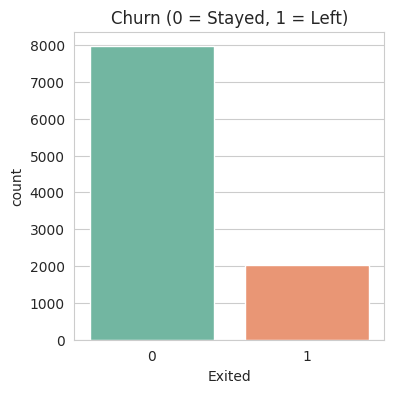

In [9]:
print(df["Exited"].value_counts())
print((df["Exited"].value_counts(normalize=True) * 100).round(1))

plt.figure(figsize=(4, 4))
sns.countplot(x="Exited", data=df, palette="Set2")
plt.title("Churn (0 = Stayed, 1 = Left)")
plt.savefig("reports/01_target_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

About **20% of customers churn**, so the data is imbalanced. Accuracy alone would be misleading (predicting 'nobody leaves' gives ~80% accuracy), so we will focus on **recall, F1 and ROC-AUC**.

### 3.2 Churn rate by categorical features

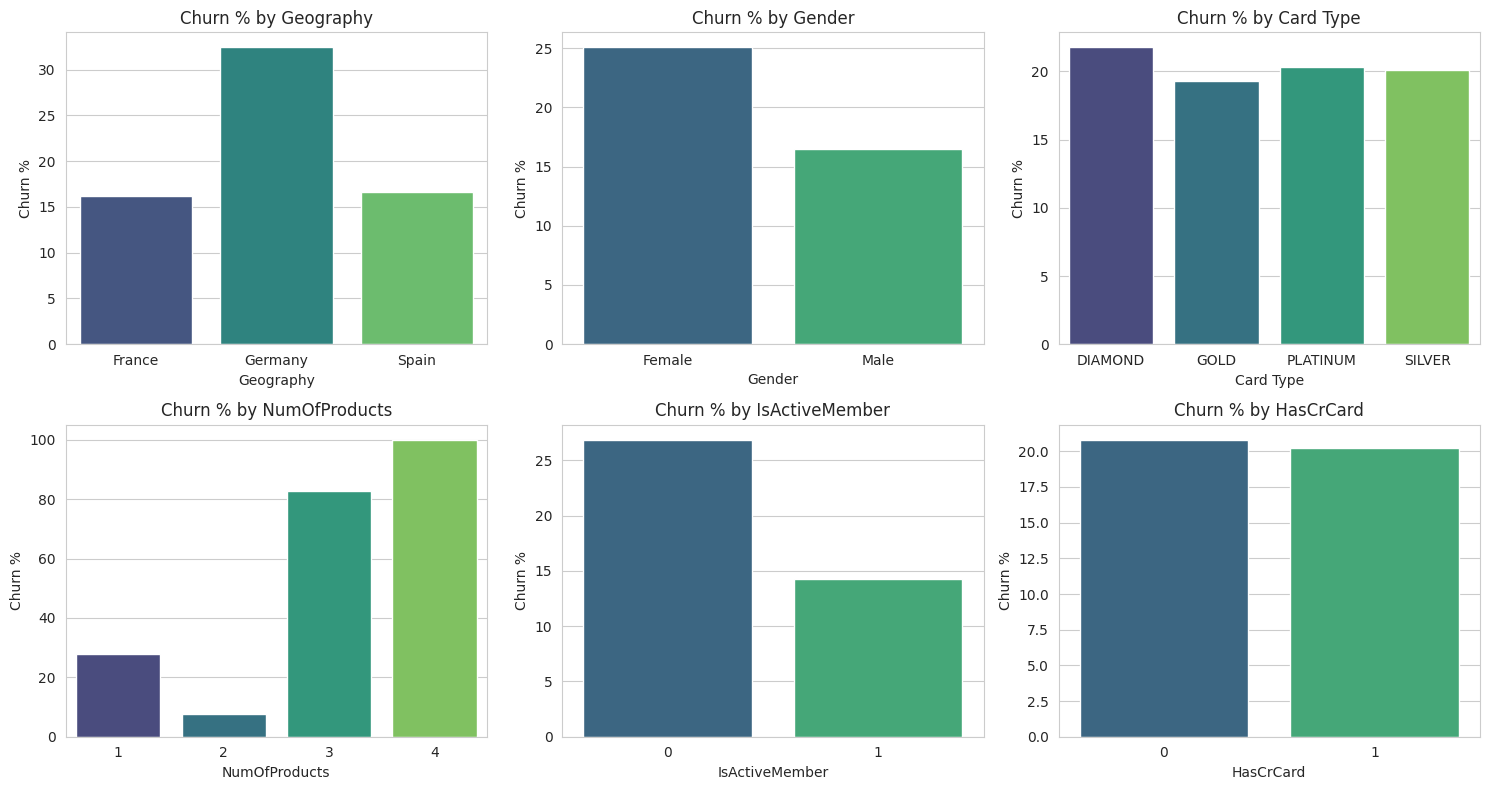

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, ["Geography", "Gender", "Card Type", "NumOfProducts", "IsActiveMember", "HasCrCard"]):
    rate = df.groupby(col)["Exited"].mean() * 100
    sns.barplot(x=rate.index, y=rate.values, ax=ax, palette="viridis")
    ax.set_title(f"Churn % by {col}")
    ax.set_ylabel("Churn %")
plt.tight_layout()
plt.savefig("reports/02_churn_by_category.png", dpi=120, bbox_inches="tight")
plt.show()

**Observations**
- **Germany** has about double the churn of France/Spain (~32% vs ~16%).
- **Female** customers churn more than male (~25% vs ~17%).
- **NumOfProducts:** customers with 3-4 products churn massively (83% and 100%), while 2 products is the safest (~8%).
- **Inactive members** churn more (~27% vs ~14%).
- `Card Type` and `HasCrCard` make almost no difference.

### 3.3 Numerical features vs churn

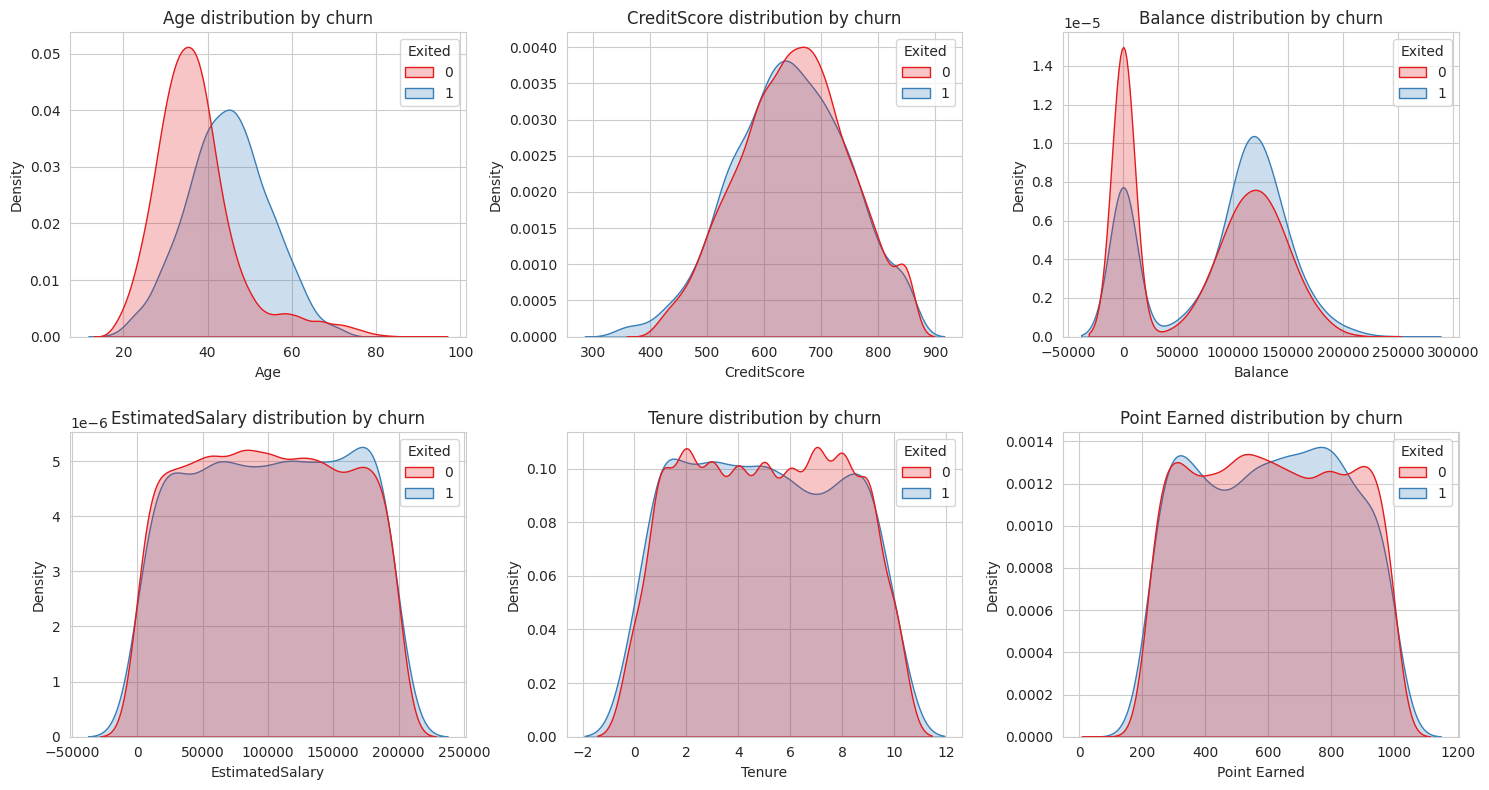

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, ["Age", "CreditScore", "Balance", "EstimatedSalary", "Tenure", "Point Earned"]):
    sns.kdeplot(data=df, x=col, hue="Exited", fill=True, common_norm=False, ax=ax, palette="Set1")
    ax.set_title(f"{col} distribution by churn")
plt.tight_layout()
plt.savefig("reports/03_numeric_distributions.png", dpi=120, bbox_inches="tight")
plt.show()

In [12]:
age_bins = pd.cut(df["Age"], [17, 30, 40, 50, 60, 100], labels=["18-30", "31-40", "41-50", "51-60", "60+"])
print((df.groupby(age_bins)["Exited"].mean() * 100).round(1))
print("\nChurn % when Balance == 0:     ", round(df[df["Balance"] == 0]["Exited"].mean() * 100, 1))
print("Churn % when Balance > 0:      ", round(df[df["Balance"] > 0]["Exited"].mean() * 100, 1))

Age
18-30     7.5
31-40    12.1
41-50    34.0
51-60    56.2
60+      24.8
Name: Exited, dtype: float64

Churn % when Balance == 0:      13.8
Churn % when Balance > 0:       24.1


**Observations**
- **Age is the strongest driver.** Churn peaks for customers aged 41-60 (34% and 56%) and is low for the under-40s.
- Customers **with a balance** churn more than those with zero balance.
- `EstimatedSalary`, `Tenure`, `Satisfaction Score` and `Point Earned` show almost no relationship with churn.

### 3.4 Correlation heatmap

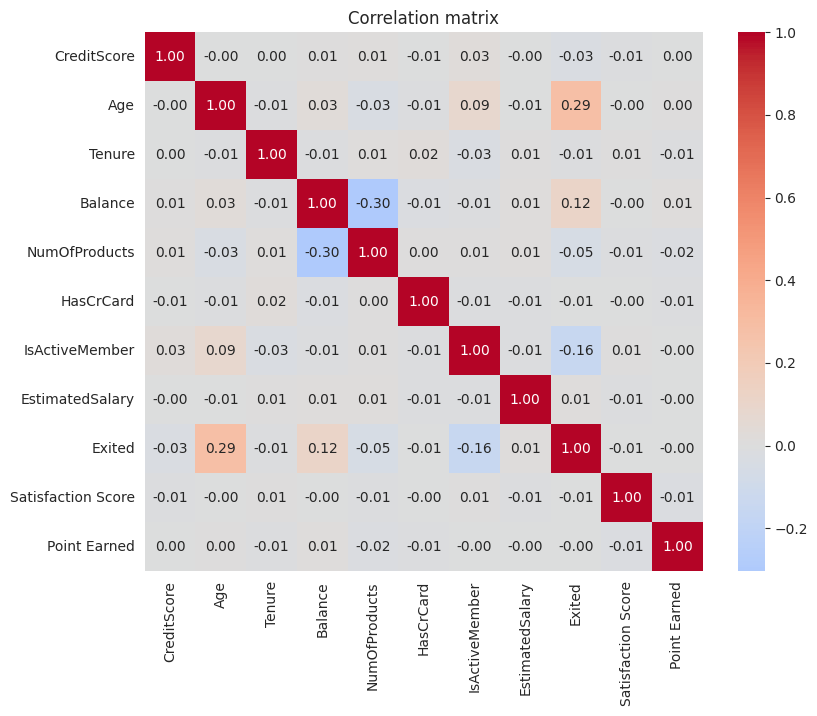

In [13]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.savefig("reports/04_correlation.png", dpi=120, bbox_inches="tight")
plt.show()

`Age` (+0.29), `IsActiveMember` (-0.16) and `Balance` (+0.12) have the strongest linear relationship with churn.

## 4. Feature engineering
New features based on what EDA showed:
- `HasBalance`: 1 if balance > 0 (zero-balance customers behave differently)
- `BalanceSalaryRatio`: balance relative to salary
- `AgeGroup`: age bands (churn jumps sharply after 40)

Then we convert text columns to numbers with one-hot encoding.

In [14]:
df_fe = df.copy()

df_fe["HasBalance"] = (df_fe["Balance"] > 0).astype(int)
df_fe["BalanceSalaryRatio"] = df_fe["Balance"] / (df_fe["EstimatedSalary"] + 1)
df_fe["AgeGroup"] = pd.cut(df_fe["Age"], [17, 30, 40, 50, 60, 100], labels=[0, 1, 2, 3, 4]).astype(int)

# Encode text columns -> numbers
df_fe["Gender"] = df_fe["Gender"].map({"Female": 0, "Male": 1})
df_fe = pd.get_dummies(df_fe, columns=["Geography", "Card Type"], drop_first=True)

print("Shape after feature engineering:", df_fe.shape)
df_fe.head()

Shape after feature engineering: (10000, 20)


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Satisfaction Score,Point Earned,HasBalance,BalanceSalaryRatio,AgeGroup,Geography_Germany,Geography_Spain,Card Type_GOLD,Card Type_PLATINUM,Card Type_SILVER
0,619,0,42,2,0.00,1,1,1,101348.88,1,2,464,0,0.000000,2,False,False,False,False,False
1,608,0,41,1,83807.86,1,0,1,112542.58,0,3,456,1,0.744670,2,False,True,False,False,False
2,502,0,42,8,159660.80,3,1,0,113931.57,1,3,377,1,1.401362,2,False,False,False,False,False
3,699,0,39,1,0.00,2,0,0,93826.63,0,5,350,0,0.000000,1,False,False,True,False,False
4,850,0,43,2,125510.82,1,1,1,79084.10,0,5,425,1,1.587035,2,False,True,True,False,False


## 5. Train / test split
80% for training, 20% for testing. `stratify=y` keeps the same churn ratio (20%) in both sets.

In [15]:
X = df_fe.drop(columns=["Exited"])
y = df_fe["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (8000, 19)  Test: (2000, 19)
Churn rate train: 0.204 | test: 0.204


## 6. Model training
We try 3 models. To deal with the 80/20 imbalance, each model is told to give **more weight to churners**:
- Logistic Regression (needs scaled data) with `class_weight="balanced"`
- Random Forest with `class_weight="balanced"`
- XGBoost with `scale_pos_weight` (ratio of non-churners to churners)

In [16]:
# Scale numbers for Logistic Regression only (fit on train, apply to test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

ratio = (y_train == 0).sum() / (y_train == 1).sum()

log_reg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
rf = RandomForestClassifier(n_estimators=200, max_depth=8, class_weight="balanced", random_state=42)
xgb = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4,
                    scale_pos_weight=ratio, random_state=42, eval_metric="logloss")

log_reg.fit(X_train_scaled, y_train)
rf.fit(X_train, y_train)
xgb.fit(X_train, y_train)
print("All 3 models trained.")

All 3 models trained.


### Compare the models on the test set

In [17]:
def get_scores(name, y_true, y_pred, y_prob):
    return {"Model": name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred),
            "ROC-AUC": roc_auc_score(y_true, y_prob)}

results = [
    get_scores("Logistic Regression", y_test, log_reg.predict(X_test_scaled), log_reg.predict_proba(X_test_scaled)[:, 1]),
    get_scores("Random Forest",       y_test, rf.predict(X_test),             rf.predict_proba(X_test)[:, 1]),
    get_scores("XGBoost",             y_test, xgb.predict(X_test),            xgb.predict_proba(X_test)[:, 1]),
]
results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.710,0.388,0.733,0.508,0.781
Random Forest,0.823,0.551,0.716,0.623,0.871
XGBoost,0.808,0.519,0.775,0.621,0.878


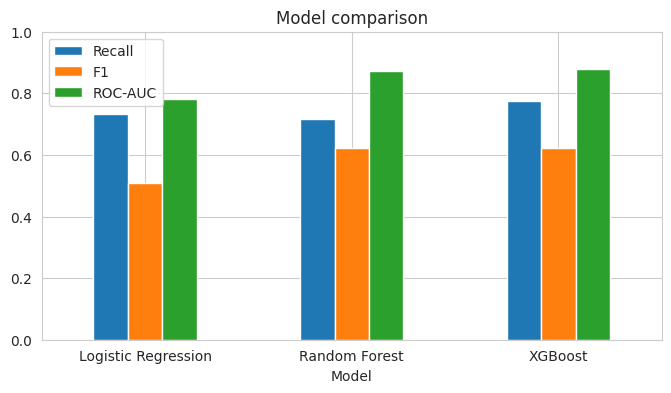

In [18]:
results_df[["Recall", "F1", "ROC-AUC"]].plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("Model comparison")
plt.ylim(0, 1)
plt.savefig("reports/05_model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

**Logistic Regression** is the weakest because churn depends on non-linear patterns (e.g. age bands, number of products). The tree-based models do much better. We tune the best one next.

## 7. Hyperparameter tuning
We tune XGBoost with `GridSearchCV` (5-fold cross-validation on the **training data only**), scoring by ROC-AUC.

In [19]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.03, 0.05, 0.1],
}
grid = GridSearchCV(
    XGBClassifier(scale_pos_weight=ratio, random_state=42, eval_metric="logloss"),
    param_grid, scoring="roc_auc", cv=5, n_jobs=-1
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 3))
best_model = grid.best_estimator_

Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
Best CV ROC-AUC: 0.86


## 8. Final evaluation on the test set

In [20]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

              precision    recall  f1-score   support

      Stayed       0.93      0.81      0.86      1592
     Churned       0.50      0.77      0.61       408

    accuracy                           0.80      2000
   macro avg       0.72      0.79      0.74      2000
weighted avg       0.84      0.80      0.81      2000

ROC-AUC: 0.876


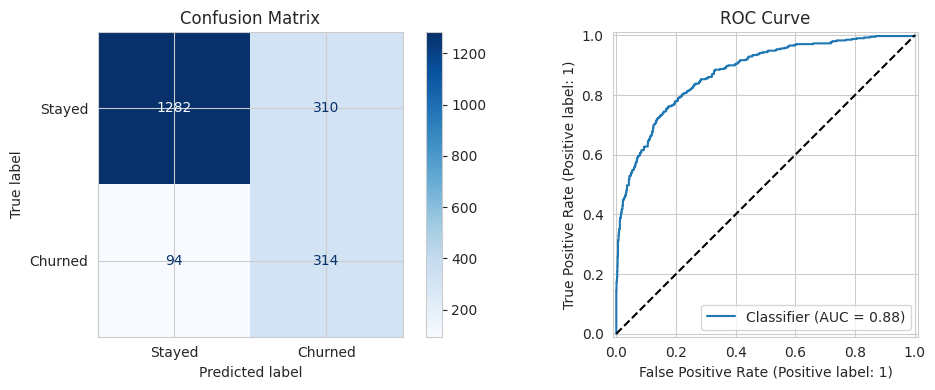

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Stayed", "Churned"], cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("ROC Curve")
plt.tight_layout()
plt.savefig("reports/06_evaluation.png", dpi=120, bbox_inches="tight")
plt.show()

### Feature importance: what drives churn?

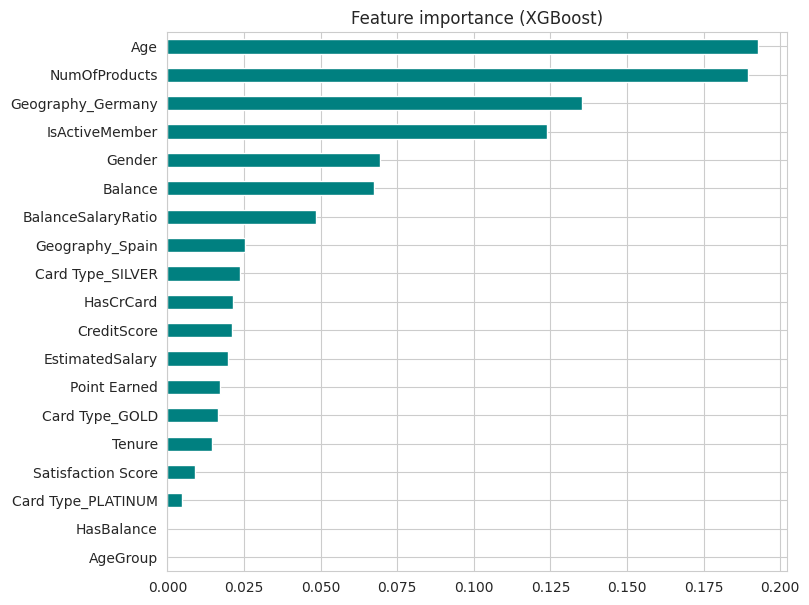

Age                  0.193
NumOfProducts        0.190
Geography_Germany    0.135
IsActiveMember       0.124
Gender               0.069
Balance              0.068
dtype: float32

In [22]:
importance = pd.Series(best_model.feature_importances_, index=X.columns).sort_values()
importance.plot(kind="barh", figsize=(8, 7), color="teal")
plt.title("Feature importance (XGBoost)")
plt.savefig("reports/07_feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()
importance.sort_values(ascending=False).head(6).round(3)

### Choosing a decision threshold
By default, a customer is flagged as "churn" when probability > 0.5. A bank may prefer to catch **more** churners (higher recall) even if it means some false alarms. Let's see the trade-off:

In [23]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_t = (y_prob >= t).astype(int)
    rows.append({"Threshold": t,
                 "Precision": precision_score(y_test, pred_t),
                 "Recall": recall_score(y_test, pred_t),
                 "F1": f1_score(y_test, pred_t)})
pd.DataFrame(rows).set_index("Threshold").round(3)

,Precision,Recall,F1
Threshold,,,
0.3,0.352,0.919,0.509
0.4,0.432,0.853,0.573
0.5,0.503,0.770,0.609
0.6,0.588,0.669,0.626
0.7,0.684,0.583,0.630


## 9. Save the model
The Streamlit app will load this file.

In [24]:
joblib.dump({"model": best_model, "columns": list(X.columns)}, "models/churn_model.joblib")
print("Saved! Feature columns:", len(X.columns))

Saved! Feature columns: 19


## 10. Conclusion & business recommendations
- The final tuned XGBoost model reaches **ROC-AUC ≈ 0.88** and catches about **77% of customers who actually churn** (recall), at the cost of some false alarms (precision ≈ 50%). Raising the threshold trades recall for precision.
- **Biggest churn drivers (feature importance):** age (41-60), number of products, Germany, inactive membership, gender (female), and account balance.
- **Recommendations for the bank:**
  1. Run retention campaigns for **customers aged 41-60**, especially in **Germany**.
  2. Investigate why customers with **3-4 products** almost always leave (possible over-selling).
  3. Re-engage **inactive members** with offers.
  4. Use the model's probability to rank customers and contact the highest-risk ones first.
- **Limitation:** `Complain` was removed because of leakage. If complaints are logged early, it could be a very strong early-warning signal in a real system.